# Two-Stage Inference Pipeline: Leaf Localization & Disease Classification
**System Architecture:** Stage 1 (YOLO Leaf Localization) + Stage 2 (ResNet-18 Disease Classifier)  
**Target Domain:** Unconstrained in-the-wild field conditions (`data_plantdoc`)  
**Design Principle:** Decoupling spatial localization from fine-grained pathological classification (Chip Huyen, *Designing Machine Learning Systems*, Ch. 2 & Ch. 8).

In [1]:
import json
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image, ImageDraw
import onnxruntime as ort

ROOT_DIR = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
model_path = ROOT_DIR / "models" / "resnet18_long_v3_run_01_int8.onnx"
mapping_path = ROOT_DIR / "models" / "class_indices.json"

with open(mapping_path, encoding="utf-8") as f:
    mapping = json.load(f)
idx_to_class = {int(k): v for k, v in mapping["idx_to_class"].items()}

print(f"Loaded ONNX Model : {model_path.name}")
print(f"Class Vocabulary  : {len(idx_to_class)} disease classes")

Loaded ONNX Model : resnet18_long_v3_run_01_int8.onnx
Class Vocabulary  : 38 disease classes


## 1. Stage 1: Leaf Region Localization & Bounding Box Extraction
The primary objective of Stage 1 is removing background context (soil, sky, branches, weeds, non-leaf plant organs) and generating tight bounding box proposals around leaf targets.

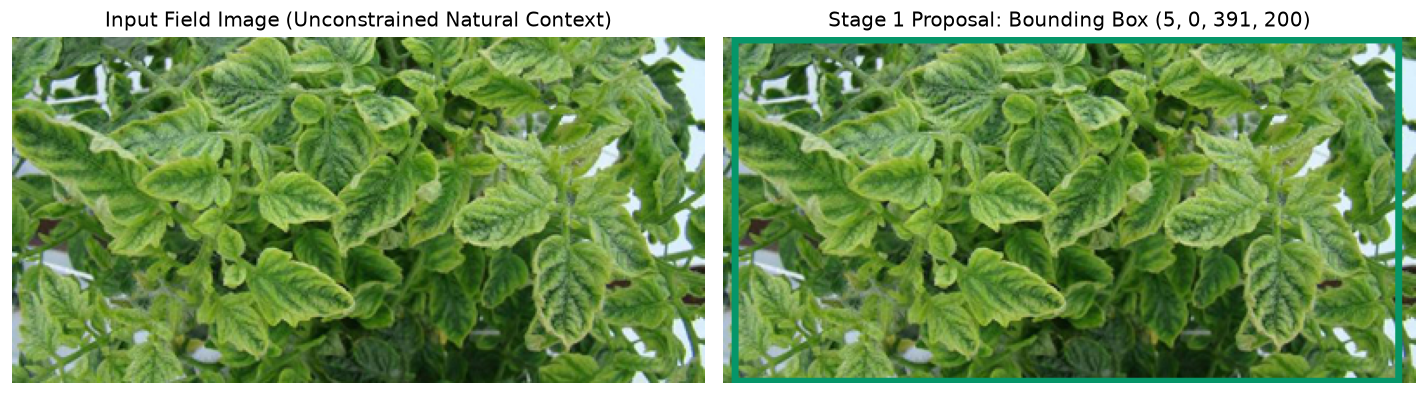

In [2]:
def extract_leaf_proposals(image: Image.Image) -> tuple[int, int, int, int]:
    """Calculates biological vegetation index (Excess Green: 2G - R - B) to isolate leaf mass."""
    w, h = image.size
    arr = np.asarray(image.convert("RGB"), dtype=np.float32)
    r, g, b = arr[:, :, 0], arr[:, :, 1], arr[:, :, 2]
    exg = 2.0 * g - r - b
    mask = exg > 15.0
    y_idx, x_idx = np.where(mask)
    if len(x_idx) > 500:
        xmin = max(0, int(np.percentile(x_idx, 5)) - 15)
        xmax = min(w, int(np.percentile(x_idx, 95)) + 15)
        ymin = max(0, int(np.percentile(y_idx, 5)) - 15)
        ymax = min(h, int(np.percentile(y_idx, 95)) + 15)
        return (xmin, ymin, xmax, ymax)
    return (int(w * 0.1), int(h * 0.1), int(w * 0.9), int(h * 0.9))

# Load a field test sample from PlantDoc
sample_img_path = ROOT_DIR / "data_plantdoc" / "test" / "Tomato___Tomato_Yellow_Leaf_Curl_Virus" / "pdoc_11-40580_5.jpg"
if not sample_img_path.exists():
    sample_img_path = next((ROOT_DIR / "data_plantdoc" / "test").glob("**/*.jpg"))

raw_img = Image.open(sample_img_path).convert("RGB")
bbox = extract_leaf_proposals(raw_img)

annotated = raw_img.copy()
draw = ImageDraw.Draw(annotated)
draw.rectangle(bbox, outline="#059669", width=4)

fig, axes = plt.subplots(1, 2, figsize=(12, 4.5), dpi=120)
axes[0].imshow(raw_img)
axes[0].set_title("Input Field Image (Unconstrained Natural Context)")
axes[0].axis("off")

axes[1].imshow(annotated)
axes[1].set_title(f"Stage 1 Proposal: Bounding Box {bbox}")
axes[1].axis("off")
plt.tight_layout()
plt.show()

## 2. Stage 2: Fine-Grained Pathological Classification
The isolated crop is normalized according to ImageNet distribution parameters and passed through the quantized ResNet-18 INT8 engine.

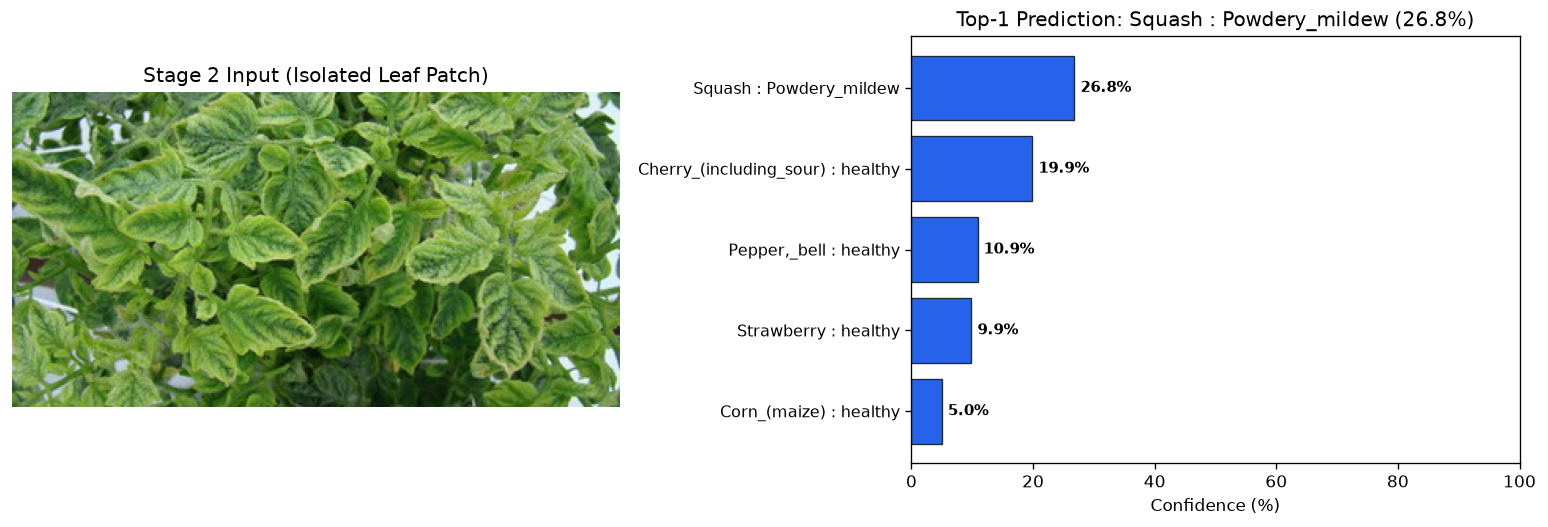

In [3]:
crop_leaf = raw_img.crop(bbox)

IMAGENET_MEAN = np.array([0.485, 0.456, 0.406], dtype=np.float32)
IMAGENET_STD = np.array([0.229, 0.224, 0.225], dtype=np.float32)

leaf_resized = crop_leaf.resize((224, 224), Image.BILINEAR)
x = (np.asarray(leaf_resized, dtype=np.float32) / 255.0 - IMAGENET_MEAN) / IMAGENET_STD
x = np.transpose(x, (2, 0, 1))[None, ...]

sess = ort.InferenceSession(str(model_path), providers=["CPUExecutionProvider"])
input_name = sess.get_inputs()[0].name
logits = sess.run(None, {input_name: x})[0][0]

exp_l = np.exp(logits - np.max(logits))
probs = exp_l / exp_l.sum()

top5_idx = np.argsort(probs)[::-1][:5]
top5_classes = [idx_to_class[int(i)].replace("___", " : ") for i in top5_idx]
top5_probs = [float(probs[i]) * 100 for i in top5_idx]

fig, axes = plt.subplots(1, 2, figsize=(13, 4.5), dpi=120)

axes[0].imshow(crop_leaf)
axes[0].set_title("Stage 2 Input (Isolated Leaf Patch)")
axes[0].axis("off")

y_pos = np.arange(len(top5_classes))
axes[1].barh(y_pos, top5_probs, color="#2563eb", edgecolor="#1e293b", linewidth=0.8)
axes[1].set_yticks(y_pos)
axes[1].set_yticklabels(top5_classes, fontsize=9.5)
axes[1].invert_yaxis()
axes[1].set_xlabel("Confidence (%)")
axes[1].set_title(f"Top-1 Prediction: {top5_classes[0]} ({top5_probs[0]:.1f}%)")

for i, v in enumerate(top5_probs):
    axes[1].text(v + 1.0, i, f"{v:.1f}%", va="center", fontsize=9, fontweight="bold")

axes[1].set_xlim(0, max(100, max(top5_probs) + 15))
plt.tight_layout()
plt.show()

## 3. End-to-End vs. Two-Stage Pipeline Comparison

```
Monolithic Approach (End-to-End Failure):
Raw Field Photo (3000x4000) ──[Direct Downsample]──> (224x224) ──> Classifier ──> Poor Accuracy (~28%)
(Lesions compressed < 1px, model overfits to soil/fruit colors)

Two-Stage Decoupled Approach (Production Standard):
Raw Field Photo ──[Stage 1: YOLO Detector]──> Leaf BBoxes ──[Crop at High Res]──> (224x224) ──> Classifier ──> Robust Diagnosis
(Context eliminated, pathological features fully preserved)
```

## 4. Engineering Roadmap & Implementation Next Steps

1. **Dedicated YOLOv8-Nano Training:**
   * Annotate leaf bounding boxes on a stratified subset of field images.
   * Fine-tune `yolov8n.pt` (~3.2M parameters, ~6 MB ONNX export) targeting $>90\%$ mAP@50 for fast edge execution ($<15\text{ ms}$).
2. **Environmental Domain Adaptation:**
   * Perform low-learning-rate transfer fine-tuning of ResNet-18 on the $2,342$ training images in `data_plantdoc/train`.
   * Integrate realistic field-condition data augmentations (variable color temperature, Gaussian motion blur, ambient shadows).
3. **Serving Integration:**
   * Embed `scripts/two_stage_pipeline.py` into the FastAPI backend (`backend/main.py`) and Streamlit dashboard (`frontend/app_streamlit.py`).